C:\Users\Malakai\AppData\Local\Temp\ipykernel_5516\3223803469.py:23: RuntimeWarning: invalid value encountered in sqrt
  return 1 + np.sqrt((r_val+u-U_0)/(r_val+delta))
C:\Users\Malakai\AppData\Local\Temp\ipykernel_5516\3223803469.py:26: RuntimeWarning: invalid value encountered in sqrt
  return 1 - np.sqrt((r_val+u-U_0)/(r_val+delta))
C:\Users\Malakai\AppData\Local\Temp\ipykernel_5516\3223803469.py:32: RuntimeWarning: divide by zero encountered in divide
  return -(epsilon_1*(U_0-u))/(epsilon_2*(U_bar - u)) #nullcline is q = this function as plotting in (u, q) phase plane


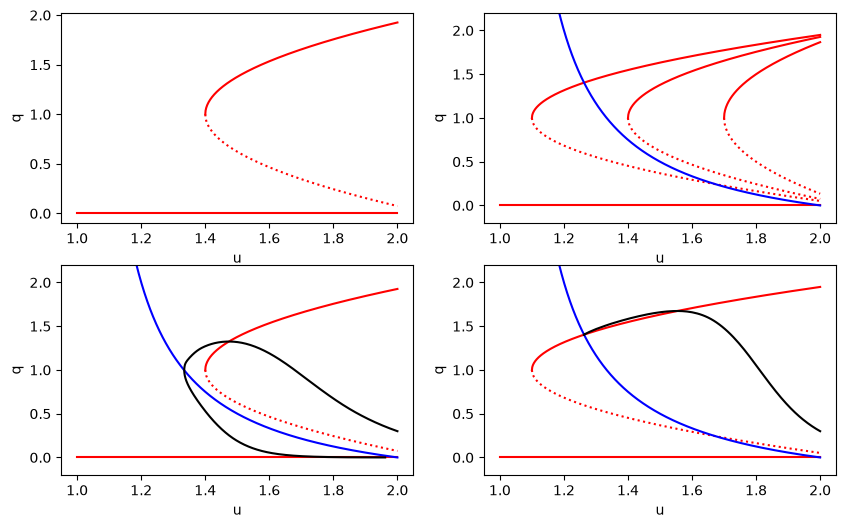

In [33]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
r = [0.3, 0.6, 0.9]
U_0 = 2 #centreline velocity
U_bar = 1 #bulk velocity
delta = 0.1
epsilon_1 = 0.1
epsilon_2 = 0.2
t0 = 0
tf = 50

def f(q, u, r_val): # q dot
    return q*( r_val + (u - U_0) - (r_val + delta)*(q - 1)**2 )

def g(q, u): # u dot
    return epsilon_1*(U_0-u) + epsilon_2*(U_bar-u)*q

def dydt(t, y, r_val):
    return(f(y[0], y[1], r_val), g(y[0],y[1]))

def q_nullcline_upper(u, r_val):
    return 1 + np.sqrt((r_val+u-U_0)/(r_val+delta))

def q_nullcline_lower(u, r_val):
    return 1 - np.sqrt((r_val+u-U_0)/(r_val+delta))

def q_nullcline_laminar(u):
    return np.zeros(np.shape(u))

def u_nullcline(u): #correted from equation 8.8 which lacks negative sign
    return -(epsilon_1*(U_0-u))/(epsilon_2*(U_bar - u)) #nullcline is q = this function as plotting in (u, q) phase plane

u_vals = np.linspace(U_bar, U_0, 1001)
t_vals = np.linspace(t0, tf, 1001)

fig, ax = plt.subplots(2, 2, figsize = (10, 6))           

ax[0,0].plot(u_vals, q_nullcline_upper(u_vals, r[1]), color='red')
ax[0,0].plot(u_vals, q_nullcline_lower(u_vals, r[1]), color='red', linestyle = "dotted")
ax[0,0].plot(u_vals, q_nullcline_laminar(u_vals), color='red')
ax[0,0].annotate("1", (0.25, 1))
ax[0,0].set_xlabel("u")
ax[0,0].set_ylabel("q")

for i in [0,1,2]:
    ax[0,1].plot(u_vals, q_nullcline_upper(u_vals, r[i]), color='red')
    ax[0,1].plot(u_vals, q_nullcline_lower(u_vals, r[i]), color='red', linestyle = "dotted")
ax[0,1].plot(u_vals, q_nullcline_laminar(u_vals), color='red')
ax[0,1].plot(u_vals, u_nullcline(u_vals), color='blue')
ax[0,1].set_ylim(-0.2, 2.2)
ax[0,1].set_xlabel("u")
ax[0,1].set_ylabel("q")

ax[1,0].plot(u_vals, q_nullcline_upper(u_vals, r[1]), color='red')
ax[1,0].plot(u_vals, q_nullcline_lower(u_vals, r[1]), color='red', linestyle = "dotted")
ax[1,0].plot(u_vals, q_nullcline_laminar(u_vals), color='red')
ax[1,0].plot(u_vals, u_nullcline(u_vals), color='blue')
ax[1,0].set_ylim(-0.2, 2.2)
ax[1,0].set_xlabel("u")
ax[1,0].set_ylabel("q")

init_point = [0.3, U_0] # starting point of the trajectory
traj_1 = solve_ivp(dydt, (t0,tf), init_point_1, t_eval=t_vals, args=(r[1],))
#note that y[0] = q, y[1] = u
ax[1,0].plot(traj_1.y[1], traj_1.y[0], color='black')

ax[1,1].plot(u_vals, q_nullcline_upper(u_vals, r[2]), color='red')
ax[1,1].plot(u_vals, q_nullcline_lower(u_vals, r[2]), color='red', linestyle = "dotted")
ax[1,1].plot(u_vals, q_nullcline_laminar(u_vals), color='red')
ax[1,1].plot(u_vals, u_nullcline(u_vals), color='blue')
ax[1,1].set_ylim(-0.2, 2.2)
ax[1,1].set_xlabel("u")
ax[1,1].set_ylabel("q")

traj_2 = solve_ivp(dydt, (t0,tf), init_point, t_eval=t_vals, args=(r[2],))
ax[1,1].plot(traj_2.y[1], traj_2.y[0], color='black')

plt.show()